# Link Corridor Ends

Link corridors are cut at both end nodes such that a link's corridor ends where the link ends. We check whether this cut is needed and whether it works on the pilot links:
- how much the round caps of the uncut buffer would add
- how much the cuts remove from the link's own corridor

<br><br>

# 0. Setup

### 0.1. Imports and Config

In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from shapely import LineString
from shapely.ops import substring

from splendor.config import CORRIDOR_RADIUS, STUDY_AREA
from splendor.io import load_network, load_raster
from splendor.landuse.corridors import get_link_corridor
from splendor.paths import network_path, basemap05_main_types_path
from splendor.plotting.landuse import plot_landuse_map

ID_COLUMN = "edge_id"
R = CORRIDOR_RADIUS
SHORT_LINK_M = 1000 # Threshold for "short" links in meters
LOSS_THRESHOLD = 0.01 # Own-corridor loss reported above this share

### 0.2. Data

In [2]:
_, edges = load_network(network_path(STUDY_AREA))
edges = edges.set_index(ID_COLUMN)
lengths = edges.geometry.length.rename("length_m")

print(f"{len(edges)} links, r = {R} m")
print(lengths.describe().round(0))

638 links, r = 100 m
count      638.0
mean      2275.0
std       1711.0
min          8.0
25%       1150.0
50%       2024.0
75%       3041.0
max      19793.0
Name: length_m, dtype: float64


<br><br>

## 1. Link Lengths

In [3]:
# Share of short links
share_short = (lengths < SHORT_LINK_M).mean()
print(f"Links shorter than {SHORT_LINK_M} m: {share_short:.1%}")

# Area added by the two half-discs (pi r^2) relative to the link's own area (2 r L)
overhead = (np.pi * R**2) / (2 * R * lengths)
print(overhead.describe(percentiles=[0.25, 0.5, 0.75, 0.9]).round(3))

Links shorter than 1000 m: 21.2%
count    638.000
mean       0.248
std        1.125
min        0.008
25%        0.052
50%        0.078
75%        0.137
90%        0.334
max       20.072
Name: length_m, dtype: float64


<br><br>

## 2. Own-Corridor Loss

In [4]:
def get_middle(line: LineString, r: float) -> LineString | None:
    """The link without its two end pieces (the last s = min(r, L/2) meters at each end), or None if nothing remains."""
    L = line.length
    s = min(r, L / 2)
    return substring(line, s, L - s) if L - 2 * s > 0 else None


def get_own_corridor_loss(line: LineString, r: float) -> float:
    """
    Share of the link's corridor removed by its end cuts although it lies within r of the link
    outside its end pieces (e.g. the far leg of a U-shaped link).
    """
    corridor = get_link_corridor(line, r)
    middle = get_middle(line, r)
    if middle is None:
        return 0.0
    removed = line.buffer(r).difference(corridor)
    lost = removed.intersection(middle.buffer(r))
    return lost.area / corridor.area


loss = pd.Series(
    [get_own_corridor_loss(line, R) for line in edges.geometry],
    index=edges.index, name="own_corridor_loss",
)

print(f"Links losing more than {LOSS_THRESHOLD:.0%} of their corridor: {(loss > LOSS_THRESHOLD).sum()}")
print(loss.describe(percentiles=[0.5, 0.9, 0.99]).round(4))
print(loss.nlargest(5).round(4))

Links losing more than 1% of their corridor: 6
count    638.0000
mean       0.0006
std        0.0051
min        0.0000
50%        0.0000
90%        0.0007
99%        0.0095
max        0.1205
Name: own_corridor_loss, dtype: float64
edge_id
605    0.1205
72     0.0209
320    0.0189
19     0.0145
210    0.0141
Name: own_corridor_loss, dtype: float64


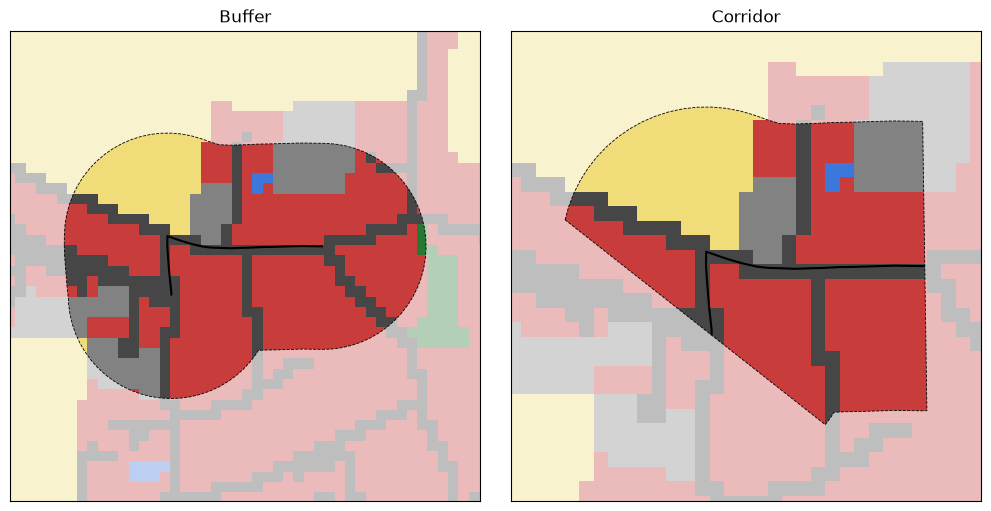

In [6]:
raster, transform, _ = load_raster(basemap05_main_types_path(STUDY_AREA))

line = edges.loc[605].geometry
fig, (ax_buffer, ax_corridor) = plt.subplots(1, 2, figsize=(10, 5), layout="constrained")
plot_landuse_map(ax_buffer, raster, transform, line, line.buffer(R))
plot_landuse_map(ax_corridor, raster, transform, line, get_link_corridor(line, R))
ax_buffer.set_title("Buffer")
ax_corridor.set_title("Corridor");

<br><br>

## 3. Conclusion

21% of the links are shorter than 1 km. For the median link, the round caps of the uncut buffer would add 8% extra to its area, and for 1/10 links more than 33%. The end cuts rarely remove corridor belonging to other parts of the link: the median loss is 0, and only 6 links lose more than 1% of their corridor. The largest is link 605 with 12%: a short link with a sharp corner close to its end, so its end piece spans the corner, the cutting line is diagonal, and land beside the final leg is removed along with the overshoot.